In [2]:
from collections import defaultdict

In [4]:
import csv
from glob import glob

In [5]:
Fams,species={},[]
for line in open('orthologous_groups_0623.txt'):
    if line.startswith("#"): continue
    fid,glt=line.strip().split('\t')
    gbs=defaultdict(list)
    for g in glt.split():
        spc,gid=g.split('_',1)
        #if spc in redSp:
        gbs[spc].append(gid)
        species.extend(gbs.keys())
    if len(list(gbs.keys()))>1:
        Fams[fid]=gbs
        #if i==5: break


In [6]:
def readGO(anf):
    gospp=defaultdict(set)
    for r in csv.reader(open(anf), delimiter='\t'):
        if r[0].startswith('#'): continue
        if len(r[0].split('_'))>1:
            spc,gid=r[0].split('_',1)
            gid=gid.split('.',1)[0]
        else:
            gid=r[0].split('.',1)[0]
        if not r[9]=='-': gospp[gid].update(r[9].split(','))
    return gospp

In [7]:
GOSp=dict()
for spa in glob("emap/*.annotations"):
    sp=spa.split('/')[1].split('.')[0]
    print(sp)
    gospp=readGO(spa)
    GOSp[sp]=gospp
    
    

Braflo
Owefus
Pecmax
Romcul
Pricau
Tricas
Sackow
Tubcor
Notgen
Ramvar
Tricor
Halspi
Octbim
Astrub
Euraff


In [22]:
for g,go in GOSp['Pecmax'].items():
    print(g,list(go)[0:10])
    break

Pecmax_LOC117314534 ['GO:0045934', 'GO:0044446', 'GO:0009987', 'GO:0042623', 'GO:0019899', 'GO:0046483', 'GO:0031324', 'GO:0022414', 'GO:0017111', 'GO:0031981']


In [17]:
from goatools.go_enrichment import GOEnrichmentStudy
from goatools.utils import read_geneset
from goatools.anno.genetogo_reader import Gene2GoReader
from goatools.obo_parser import GODag

In [2]:
import pandas as pd

In [20]:
go = GODag('go-basic.obo')

go-basic.obo: fmt(1.2) rel(2023-04-01) 46,575 Terms


### set up familiy level GO enrichments

In [8]:
GOFam=defaultdict(set)
for f,gbs in Fams.items(): 
    #print(f,gbs)
    for s in gbs:
        if s in GOSp:
            gosp=GOSp[s]
            gost=[gosp[g] for g in gbs[s] if g in gosp]
            gostf=[s for s in gost if not s==set()]
            #print(f,s,gostf)
            for s in gostf:
                GOFam[f].update(s)

                

In [ ]:
famGO = GOEnrichmentStudy(list(GOFam.keys()), GOFam, go,
                         propagate_counts=True,
                         alpha=0.05,
                         methods=['fdr_bh'])

In [ ]:
list(Fams.items())[0]

In [11]:
NodRef={'26':'Protostomia','24':'Ecdysozoa','20':'Cryptovermes','12':'Panarthropoda','8':'A_Onych+EuArth','6':'Euarthropoda','5':'Mandibulata',
        '2':'Pancrustacea','21':'Priapulid','14':'Priapulimorpha','23':'Mollusca','25':'Spiralia','22':'Vermizoa'}

In [19]:
caFam={}
for fcp in glob('cafe_final/fam_tree_*'):
    ch,nd=fcp.split('/')[1].split('.')[0].split('_')[2:4]
    nd=nd.replace('<','').replace('>','')
    cog=[l.strip() for l in open(fcp)]
    print(nd,NodRef.get(nd,nd),ch,len(cog))
    chs='exp' if ch=='expansions' else 'cont'
    caFam[f"{NodRef.get(nd,nd)}_{chs}"]=cog

2 Pancrustacea contractions 2
Tricas Tricas expansions 83
Euraff Euraff contractions 8
12 Panarthropoda expansions 4
24 Ecdysozoa expansions 0
Carrot Carrot contractions 0
Tubcor Tubcor contractions 22
25 Spiralia expansions 99
Halspi Halspi expansions 151
Owefus Owefus expansions 163
Ramvar Ramvar expansions 71
22 Vermizoa expansions 37
8 A_Onych+EuArth contractions 2
Epibro Epibro expansions 138
20 Cryptovermes contractions 79
Notgen Notgen expansions 227
Pricau Pricau contractions 10
14 Priapulimorpha expansions 44
Octbim Octbim contractions 32
5 Mandibulata contractions 18
Romcul Romcul contractions 11
Pecmax Pecmax contractions 3
Tricor Tricor contractions 0
6 Euarthropoda expansions 21
21 Priapulid contractions 5
23 Mollusca expansions 20
Tubcor Tubcor expansions 183
5 Mandibulata expansions 5
22 Vermizoa contractions 0
20 Cryptovermes expansions 6
Halspi Halspi contractions 11
6 Euarthropoda contractions 7
14 Priapulimorpha contractions 3
Tricas Tricas contractions 11
Euraff Eur

In [20]:
gal=[]
for ndc,clf in caFam.items():
    print(ndc,len(clf),'families...')
    if len(clf)==0: continue
    fgo=famGO.run_study(clf)
    fgl=[[l.NS,l.GO,l.name,l.enrichment,l.ratio_in_study[0],l.ratio_in_pop[0],l.p_fdr_bh,l.p_uncorrected] for l in fgo]
    gonl=pd.DataFrame(fgl,columns =['Ontology','Term','Name','Enrich','Study','Pop','p_fdr_bh','p_uncor'])
    gonl['Node']=ndc
    gal.append(gonl)

Pancrustacea_cont 2 families...

Runing  Ontology Analysis: current study set of 2 IDs.
100%      2 of      2 study items found in association
100%      2 of      2 study items found in population(11117)
Calculating 23,649 uncorrected p-values using fisher_scipy_stats
  23,649 terms are associated with 11,117 of 11,117 population items
     488 terms are associated with      2 of      2 study items
  METHOD fdr_bh:
       0 GO terms found significant (< 0.05=alpha) (  0 enriched +   0 purified): statsmodels fdr_bh
       0 study items associated with significant GO IDs (enriched)
       0 study items associated with significant GO IDs (purified)
Tricas_exp 83 families...

Runing  Ontology Analysis: current study set of 83 IDs.
100%     79 of     79 study items found in association
 95%     79 of     83 study items found in population(11117)
Calculating 23,649 uncorrected p-values using fisher_scipy_stats
  23,649 terms are associated with 11,117 of 11,117 population items
   6,958 term

In [21]:
cafendgo=pd.concat(gal, axis=0)

In [22]:
cafendgor=cafendgo[cafendgo['p_fdr_bh']<0.05]

In [32]:
cafendgor['GeneFamInStudy']=Lgnit

/var/folders/r4/rsb8nm392mz0l479x9lmyss80000gn/T/ipykernel_68895/2313938878.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cafendgor['GeneFamInStudy']=Lgnit


In [36]:
cafendgor.to_csv("Cafe_priap_GO.tsv",sep='\t',index=False)

In [35]:
cafendgor[(cafendgor['Node']=='Priapulid_exp')]

,Ontology,Term,Name,Enrich,Study,Pop,p_fdr_bh,p_uncor,Node,GeneFamInStudy
0,BP,GO:0060541,respiratory system development,e,14,736,0.018731,3.562145e-06,Priapulid_exp,"Rl21|Chac2|Eipr1|Ubcd4,Ube2k|Dyh10-1,Dyh10-2,D..."
1,BP,GO:0001525,angiogenesis,e,10,356,0.018731,3.960269e-06,Priapulid_exp,"Rl21|Ubcd4,Ube2k|||E2ak1|F184b,F184a|Mle3|Tm22..."
3874,CC,GO:0009986,cell surface,e,16,749,0.002803,1.185419e-07,Priapulid_exp,"Rl21|Dyh10-1,Dyh10-2,Dyh1-1,Dyh1-4,Dyh1-2,Dyh1..."
3875,CC,GO:0005576,extracellular region,e,23,1737,0.005592,5.711766e-07,Priapulid_exp,"Rl21|Chac2|Rs15a|Tnpo1-2,Tnpo1-1|Ubcd4,Ube2k|D..."
3876,CC,GO:0016020,membrane,e,43,5626,0.005592,7.093408e-07,Priapulid_exp,"Sc31a-4|Rl21|Chac2|Rs15a|Iyd1|Tnpo1-2,Tnpo1-1|..."
3877,CC,GO:0031984,organelle subcompartment,e,20,1614,0.049276,1.299668e-05,Priapulid_exp,"Chac2|Rs15a|Eipr1|Smu1||Caps2,Caps1-3,Caps1-2,..."
3878,CC,GO:0031090,organelle membrane,e,30,3237,0.049276,1.458537e-05,Priapulid_exp,Rl21|Chac2|Rs15a|Iyd1|Zn598|Eipr1|Smu1|Ttc23|U...


In [232]:
#for GO2Fam['GO:0060541']

In [23]:
cafendgor

,Ontology,Term,Name,Enrich,Study,Pop,p_fdr_bh,p_uncor,Node
0,BP,GO:0006629,lipid metabolic process,e,35,1329,6.211373e-09,5.653045e-13,Tricas_exp
1,BP,GO:0009605,response to external stimulus,e,51,2978,1.223743e-08,2.069843e-12,Tricas_exp
2,BP,GO:0048878,chemical homeostasis,e,34,1326,1.481821e-08,3.132946e-12,Tricas_exp
3,BP,GO:0008202,steroid metabolic process,e,18,316,2.046433e-08,5.192017e-12,Tricas_exp
4,BP,GO:0014070,response to organic cyclic compound,e,35,1443,2.145768e-08,6.351380e-12,Tricas_exp
...,...,...,...,...,...,...,...,...,...
10383,MF,GO:0140326,ATPase-coupled intramembrane lipid transporter...,e,3,18,4.583828e-02,8.039967e-03,Pricau_exp
10384,MF,GO:0003725,double-stranded RNA binding,e,7,99,4.896082e-02,8.633203e-03,Pricau_exp
10385,MF,GO:0032027,myosin light chain binding,e,4,35,4.959753e-02,8.774835e-03,Pricau_exp
10386,MF,GO:0019842,vitamin binding,e,8,124,4.964410e-02,8.785174e-03,Pricau_exp


In [9]:
Lfnit,Lgnit=[],[]
for i,r in cafendgor.iterrows():
    fit=GO2Fam[r['Term']]
    fnit=[f for f in caFam[r['Node']] if f in fit]
    gnit='|'.join([','.join(f2gn[f]) for f in fnit])
    #print(r['Name'],len(caFam[r['Node']]),len(fit),len(fnit),'|'.join(fnit),gnit)#GO2Fam[f for f in fit if f in caFam[r['Node']]]
    Lfnit.append('|'.join(fnit))
    Lgnit.append(gnit)
    

NameError: name 'cafendgor' is not defined

In [ ]:
Lgnit

In [54]:
GO2Fam=defaultdict(list)
for g,gots in GOFam.items():
    for gt in gots:
        GO2Fam[gt].append(g)
    

#### create a family to gene name dict

In [30]:
PcaNfo=pd.read_csv("~/Dropbox/Genomes/Priapulid/Analyses/Data_tables/Pcau_genes_info.txt",sep='\t')

In [108]:
gid2gnm={} 

In [109]:
gid2gnm['Pcau']={r['gid']:r['gname'] for i,r in gnfo.iterrows() if not r['gname'].startswith('Unchar')}

In [110]:
gid2gnm['Arub']={r[-1]:r[-2] for r in csv.reader(open('AstRub_ahp_wn.bed'),delimiter='\t') if not r[-2].startswith('Unchar')}

In [111]:
gid2gnm['Ofus']={r[0].split('.')[0]:r[1] for r in csv.reader(open('Ofus_gene2name_list.txt'),delimiter='\t') if not r[1]=='.'}

In [ ]:
list(GO2Fam.items())[0]

In [112]:
fid2gnm={}

In [113]:
fid2gnm['Pcau']={f:[gid2gnm['Pcau'][g] for g in gbs['Pricau'] if g in gid2gnm['Pcau']]for f,gbs in Fams.items()}

In [114]:
fid2gnm['Arub']={f:[gid2gnm['Arub'][g] for g in gbs['Astrub'] if g in gid2gnm['Arub']]for f,gbs in Fams.items()}

In [115]:
fid2gnm['Ofus']={f:[gid2gnm['Ofus'][g] for g in gbs['Owefus'] if g in gid2gnm['Ofus']]for f,gbs in Fams.items()}

In [116]:
fid2gnm['Ofus']['OG_1']

['HMDH']

_______________

In [89]:
GO2Gene=defaultdict(list)
for g,gots in GOSp['Pargot'].items():
    for gt in gots:
        GO2Gene[gt].append(g)
    

In [30]:
GO2Gene=defaultdict(list)
for g,gots in GOSp['Braflo'].items():
    for gt in gots:
        GO2Gene[gt].append(g)

In [ ]:
print(GO2Fam['GO:0055085'])



In [36]:
for g in GO2Gene['GO:0034080']:
    for f in Fams: 
        if g.split('_')[1] in Fams[f]:
            print(f)

In [90]:
PgotNames={r[0]:r[1] for r in csv.reader(open("/Users/fmarletaz/Dropbox/Genomes/Paraspadella/Annotation/Pgot_names_eq.txt"),delimiter='\t')}

In [93]:
termGnm=[]
for term in go_df['Term']:
    termGenes=set(GO2Gene[term]).intersection(set(gfN11))
    #print(term,len(termGenes))
    #print(term,len(termGenes),[PgotNames[g] for g in termGenes][0:50])
    termGnm.append(','.join(sorted([PgotNames[g] for g in termGenes])))
    #PgotNames.get(g,'NA')
    #break

In [94]:
go_df['Genes']=termGnm

In [104]:
go_df.to_csv('chaeto_expand_GO.tsv',sep='\t',index=False)

## try to do family level GO

In [16]:
GOFam=defaultdict(set)
for f,gbs in Fams.items(): 
    #print(f,gbs)
    for s in gbs:
        if s in GOSp:
            gosp=GOSp[s]
            gost=[gosp[g] for g in gbs[s] if g in gosp]
            gostf=[s for s in gost if not s==set()]
            #print(f,s,gostf)
            for s in gostf:
                GOFam[f].update(s)

                

In [ ]:
list(GOFam.items())[0]

### Try family losses at relevant nodes 

In [11]:
import pandas as pd

In [12]:
fgl=pd.read_csv('ortho0623_GainLoss.txt',sep='\t')

In [13]:
rvClades={'Ecdysozoa','Priapulida','Ecdy_A','Nematoda','Panarthropoda','Tardigrada','Euarthropoda','Chelicerata','Mandibulata',
          'Myriapoda','Pancrustacea','Crustacea','B','C','Insecta'}

In [14]:
rvLoss=defaultdict(list)
PhyloSt={}
for i,r in fgl.iterrows():
    lossCld=str(r['Losses']).split(',')
    PhyloSt[r['FID']]=r['Strata']
    #print(lossCld)
    for cl in rvClades:
        if cl in lossCld:
            rvLoss[cl].append(r['FID'])


In [ ]:
for f,g in GOFam.items():
    print(f,g)
    break

In [ ]:
famGO = GOEnrichmentStudy(list(GOFam.keys()), GOFam, go,
                         propagate_counts=True,
                         alpha=0.05,
                         methods=['fdr_bh'])

In [22]:
gel=[]
for cl,clf in rvLoss.items():
    print(cl,len(clf),'families...')
    
    fgo=famGO.run_study(clf)
    fgl=[[l.NS,l.GO,l.name,l.enrichment,l.ratio_in_study[0],l.ratio_in_pop[0],l.p_fdr_bh,l.p_uncorrected] for l in fgo]
    gonl=pd.DataFrame(fgl,columns =['Ontology','Term','Name','Enrich','Study','Pop','p_fdr_bh','p_uncor'])
    gonl['Node']=cl
    gel.append(gonl)
    

Ecdysozoa 1059 families...

Runing  Ontology Analysis: current study set of 1059 IDs.
100%    435 of    435 study items found in association
 41%    435 of  1,059 study items found in population(11117)
Calculating 23,649 uncorrected p-values using fisher_scipy_stats
  23,649 terms are associated with 11,117 of 11,117 population items
   8,992 terms are associated with    435 of  1,059 study items
  METHOD fdr_bh:
      67 GO terms found significant (< 0.05=alpha) (  1 enriched +  66 purified): statsmodels fdr_bh
       6 study items associated with significant GO IDs (enriched)
     417 study items associated with significant GO IDs (purified)
Tardigrada 4922 families...

Runing  Ontology Analysis: current study set of 4922 IDs.
100%  3,046 of  3,046 study items found in association
 62%  3,046 of  4,922 study items found in population(11117)
Calculating 23,649 uncorrected p-values using fisher_scipy_stats
  23,649 terms are associated with 11,117 of 11,117 population items
  17,903 te

In [25]:
allndgo=pd.concat(gel, axis=0)

In [26]:
allndgo

,Ontology,Term,Name,Enrich,Study,Pop,p_fdr_bh,p_uncor,Node
0,BP,GO:0043123,positive regulation of I-kappaB kinase/NF-kapp...,e,16,146,0.061068,0.000186,Ecdysozoa
1,BP,GO:0042104,positive regulation of activated T cell prolif...,e,5,16,0.082985,0.000274,Ecdysozoa
2,BP,GO:0006919,activation of cysteine-type endopeptidase acti...,e,15,139,0.097707,0.000347,Ecdysozoa
3,BP,GO:0097527,necroptotic signaling pathway,e,4,10,0.106909,0.000402,Ecdysozoa
4,BP,GO:0032218,riboflavin transport,e,3,5,0.126422,0.000561,Ecdysozoa
...,...,...,...,...,...,...,...,...,...
23644,MF,GO:0050104,L-gulonate 3-dehydrogenase activity,p,0,4,1.000000,1.000000,Mandibulata
23645,MF,GO:0000253,3-keto sterol reductase activity,p,0,9,1.000000,1.000000,Mandibulata
23646,MF,GO:0043754,dihydrolipoyllysine-residue (2-methylpropanoyl...,p,0,2,1.000000,1.000000,Mandibulata
23647,MF,GO:0098604,adenosylselenohomocysteinase activity,p,0,1,1.000000,1.000000,Mandibulata


In [24]:
allndgo[(allndgo['Pop'] == 0) & (allndgo['Ontology']=='BP')]

,Ontology,Term,Name,Enrich,Study,Pop,p_fdr_bh,p_uncor,Node


In [45]:
allndgo[allndgo['p_fdr_bh'] <0.05].to_csv('EcdysoLoss_GONodes.txt',sep='\t',index=False)

In [84]:
from numpy import log2

In [99]:
allndgo['lg2enr']=log2(allndgo.Study/allndgo.Pop)

/Users/fmarletaz/miniconda3/envs/py39/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [128]:
selndgo=allndgo[(allndgo['p_fdr_bh'] <0.05) & (allndgo['Enrich']=='e')]

In [125]:
Lfnit,Lgnit_of,Lgnit_ar=[],[],[]
Snit=defaultdict(list)
for i,r in selndgo.iterrows():
    t=r['Term']
    fit=GO2Fam[t]
    fnit=[f for f in rvLoss[r['Node']] if f in fit]
    Lfnit.append('|'.join(fnit))
    gnit_of='|'.join([','.join(list(set(fid2gnm['Ofus'][f]))) for f in fnit])
    gnit_ar='|'.join([','.join(list(set(fid2gnm['Arub'][f]))) for f in fnit])
    Lgnit_of.append(gnit_of)
    Lgnit_ar.append(gnit_ar)
    #print(t,fnit,[','.join(list(set(fid2gnm['Ofus'][f]))) for f in fnit])#,[','.join(fid2gnm['Arub'][f]) for f in fnit],[','.join(fid2gnm['Arub'][f]) for f in fnit])
    #for s in ['Arub','Pcau','Ofus']:
    #    Snit[s].append('|'.join([','.join(fid2gnm[s][f]) for f in fnit]))
    #for s in ['Arub','Pcau','Ofus']:
    #    gnit[s]='|'.join([','.join(fid2gnm[s][f]) for f in fnit])
    #print(r['Name'],len(jlDict[r['Node']]),len(fit),len(fnit),'|'.join(fnit),gnit)#GO2Fam[f for f in fit if f in caFam[r['Node']]]
    #Lfnit.append('|'.join(fnit))
    #Lgnit.append(gnit)
    #break

In [129]:
selndgo['GNIT_Ofus']=Lgnit_of
selndgo['GNIT_Arub']=Lgnit_ar
selndgo['FNIT']=Lfnit

/var/folders/_5/p5qq2lnd6tgdm2p0l_pdmcnc0000gn/T/ipykernel_348/229180636.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  selndgo['GNIT_Ofus']=Lgnit_of
/var/folders/_5/p5qq2lnd6tgdm2p0l_pdmcnc0000gn/T/ipykernel_348/229180636.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  selndgo['GNIT_Arub']=Lgnit_ar
/var/folders/_5/p5qq2lnd6tgdm2p0l_pdmcnc0000gn/T/ipykernel_348/229180636.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_

In [131]:
selndgo.to_csv('EcdysoLoss_GONodes_sel.txt',sep='\t',index=False)

In [ ]:
Lfnit,Lgnit=[],[]
for i,r in shardndgo.iterrows():
    fit=GO2Fam[r['Term']]
    fnit=[f for f in rvLoss[r['Node']] if f in fit]
    gnit='|'.join([','.join(fid2gnm['Arub'[f]) for f in fnit])
    print(r['Name'],len(jlDict[r['Node']]),len(fit),len(fnit),'|'.join(fnit),gnit)#GO2Fam[f for f in fit if f in caFam[r['Node']]]
    Lfnit.append('|'.join(fnit))
    Lgnit.append(gnit)
    

## Joint losses 

In [74]:
from itertools import combinations

In [75]:
jlDict={}
for cl1,cl2 in combinations(rvClades,2):
    jtfam=set(rvLoss[cl1]).intersection(set(rvLoss[cl2]))
    if len(jtfam)>0:
        print(cl1,cl2,len(jtfam))
        jlDict[f"{cl1}_{cl2}"]=list(jtfam)

Mandibulata Tardigrada 317
Mandibulata Nematoda 268
Mandibulata Priapulida 141
Tardigrada Chelicerata 2108
Tardigrada Nematoda 3249
Tardigrada Priapulida 1157
Tardigrada Myriapoda 1128
Tardigrada Crustacea 516
Tardigrada Pancrustacea 722
Tardigrada B 371
Tardigrada Insecta 611
Tardigrada C 1147
Panarthropoda Priapulida 210
Chelicerata Nematoda 1941
Chelicerata Priapulida 812
Chelicerata Myriapoda 1044
Chelicerata Crustacea 398
Chelicerata Pancrustacea 596
Chelicerata B 221
Chelicerata Insecta 347
Chelicerata C 1056
Nematoda Priapulida 1129
Nematoda Myriapoda 993
Nematoda Crustacea 526
Nematoda Pancrustacea 663
Nematoda B 322
Nematoda Insecta 525
Nematoda C 1030
Priapulida Myriapoda 571
Priapulida Crustacea 221
Priapulida Pancrustacea 211
Priapulida B 152
Priapulida Insecta 198
Priapulida C 404
Myriapoda Crustacea 395
Myriapoda B 221
Myriapoda Insecta 338
Myriapoda C 684
Crustacea B 291
Crustacea Insecta 301


In [139]:
from collections import Counter

In [143]:
PhyloSt['OG_7776']

KeyError: 'OG_7776'

In [ ]:
jlDict['Tardigrada_Nematoda']

In [147]:
Counter([PhyloSt.get(f,'NA') for f in jlDict['Tardigrada_Nematoda']])

Counter({'Eumetazoa': 385,
         'Metazoa': 1367,
         'Protostomia': 575,
         'Ecdysozoa': 572,
         'Bilateria': 350})

In [76]:
gol=[]
for cl,clf in jlDict.items():
    print(cl,len(clf),'families...')
    fgo=famGO.run_study(clf)
    fgl=[[l.NS,l.GO,l.name,l.enrichment,l.ratio_in_study[0],l.ratio_in_pop[0],l.p_fdr_bh,l.p_uncorrected] for l in fgo]
    gonl=pd.DataFrame(fgl,columns =['Ontology','Term','Name','Enrich','Study','Pop','p_fdr_bh','p_uncor'])
    gonl['Node']=cl
    gol.append(gonl)

Mandibulata_Tardigrada 317 families...

Runing  Ontology Analysis: current study set of 317 IDs.
100%    183 of    183 study items found in association
 58%    183 of    317 study items found in population(11117)
Calculating 23,649 uncorrected p-values using fisher_scipy_stats
  23,649 terms are associated with 11,117 of 11,117 population items
   6,121 terms are associated with    183 of    317 study items
  METHOD fdr_bh:
       0 GO terms found significant (< 0.05=alpha) (  0 enriched +   0 purified): statsmodels fdr_bh
       0 study items associated with significant GO IDs (enriched)
       0 study items associated with significant GO IDs (purified)
Mandibulata_Nematoda 268 families...

Runing  Ontology Analysis: current study set of 268 IDs.
100%    150 of    150 study items found in association
 56%    150 of    268 study items found in population(11117)
Calculating 23,649 uncorrected p-values using fisher_scipy_stats
  23,649 terms are associated with 11,117 of 11,117 populatio

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x120d13670>>
Traceback (most recent call last):
  File "/Users/fmarletaz/miniconda3/envs/py39/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 770, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


KeyboardInterrupt: 

In [81]:
shardndgo=pd.concat(gol, axis=0)

In [132]:
shardndgo

,Ontology,Term,Name,Enrich,Study,Pop,p_fdr_bh,p_uncor,Node
0,BP,GO:1900046,regulation of hemostasis,e,8,109,1.0,0.000427,Mandibulata_Tardigrada
1,BP,GO:0030193,regulation of blood coagulation,e,8,109,1.0,0.000427,Mandibulata_Tardigrada
2,BP,GO:0050818,regulation of coagulation,e,8,115,1.0,0.000611,Mandibulata_Tardigrada
3,BP,GO:0051490,negative regulation of filopodium assembly,e,3,11,1.0,0.000657,Mandibulata_Tardigrada
4,BP,GO:0002523,leukocyte migration involved in inflammatory r...,e,4,28,1.0,0.001068,Mandibulata_Tardigrada
...,...,...,...,...,...,...,...,...,...
23644,MF,GO:0050104,L-gulonate 3-dehydrogenase activity,p,0,4,1.0,1.000000,Nematoda_Pancrustacea
23645,MF,GO:0000253,3-keto sterol reductase activity,p,0,9,1.0,1.000000,Nematoda_Pancrustacea
23646,MF,GO:0043754,dihydrolipoyllysine-residue (2-methylpropanoyl...,p,0,2,1.0,1.000000,Nematoda_Pancrustacea
23647,MF,GO:0098604,adenosylselenohomocysteinase activity,p,0,1,1.0,1.000000,Nematoda_Pancrustacea


In [135]:
Lfnit,Lgnit_of,Lgnit_ar=[],[],[]
for i,r in sang.iterrows():
    fit=GO2Fam[r['Term']]
    fnit=[f for f in jlDict[r['Node']] if f in fit]
    #gnit='|'.join([','.join(f2gn[f]) for f in fnit])
    gnit_of='|'.join([','.join(list(set(fid2gnm['Ofus'][f]))) for f in fnit])
    gnit_ar='|'.join([','.join(list(set(fid2gnm['Arub'][f]))) for f in fnit])
    Lgnit_of.append(gnit_of)
    Lgnit_ar.append(gnit_ar)
    #print(r['Name'],len(jlDict[r['Node']]),len(fit),len(fnit),'|'.join(fnit),gnit)#GO2Fam[f for f in fit if f in caFam[r['Node']]]
    Lfnit.append('|'.join(fnit))
    Lgnit.append(gnit)
    

In [136]:
sang['GNIT_Ofus']=Lgnit_of
sang['GNIT_Arub']=Lgnit_ar
sang['FNIT']=Lfnit

/var/folders/_5/p5qq2lnd6tgdm2p0l_pdmcnc0000gn/T/ipykernel_348/2955965447.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sang['GNIT_Ofus']=Lgnit_of
/var/folders/_5/p5qq2lnd6tgdm2p0l_pdmcnc0000gn/T/ipykernel_348/2955965447.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sang['GNIT_Arub']=Lgnit_ar
/var/folders/_5/p5qq2lnd6tgdm2p0l_pdmcnc0000gn/T/ipykernel_348/2955965447.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_ind

In [90]:
sang=shardndgo[(shardndgo['p_fdr_bh']<0.05) & (shardndgo['Enrich']=='e')]

In [138]:
sang.to_csv('Joint_losses_GO.txt',sep='\t',index=False)

In [137]:
sang

,Ontology,Term,Name,Enrich,Study,Pop,p_fdr_bh,p_uncor,Node,GNIT_Ofus,GNIT_Arub,FNIT
5410,MF,GO:0003824,catalytic activity,e,415,5249,0.010236,9.522305e-06,Tardigrada_Chelicerata,"|PHLD|PAR14,PAR15|||NUD15|CBWD1|CBPQ|TIC32,RDH...","||||Mycb2-1|Nudt7-1|Cbwd1|Cbpq|Rdh13-7,Rdh14-1...",OG_12396|OG_7161|OG_5308|OG_7851|OG_4802|OG_43...
0,BP,GO:0034340,response to type I interferon,e,17,39,0.002189,1.277293e-05,Tardigrada_Nematoda,"|MYD88|PATS1,CED3,ROCO4,CSPA|TRIM2|TRAD1|IRF4,...","|Myd88|Neul1-3,Lrrk2-1|Trim2-2,Tri56-5,Tri45-2...",OG_6492|OG_11603|OG_6347|OG_11756|OG_3215|OG_5...
1,BP,GO:0034080,CENP-A containing chromatin assembly,e,16,38,0.005295,3.873574e-05,Tardigrada_Nematoda,||CENPI|MIS18|CENPP|CENPM|CENPK||KNL1||ANO39|C...,|Cenpc|Cenpi|Ms18a||Cenpm|Cenpk||||Ano39-1|Cen...,OG_14568|OG_10717|OG_5847|OG_2350|OG_13979|OG_...
2,BP,GO:0031055,chromatin remodeling at centromere,e,16,44,0.024203,3.039630e-04,Tardigrada_Nematoda,||CENPI|MIS18|CENPP|CENPM|CENPK||KNL1||ANO39|C...,|Cenpc|Cenpi|Ms18a||Cenpm|Cenpk||||Ano39-1|Cen...,OG_14568|OG_10717|OG_5847|OG_2350|OG_13979|OG_...
3,BP,GO:0060337,type I interferon-mediated signaling pathway,e,11,25,0.028968,4.017684e-04,Tardigrada_Nematoda,"|MYD88|PATS1,CED3,ROCO4,CSPA|TRAD1|IRF4,IRF2|O...","|Myd88|Neul1-3,Lrrk2-1|Trad1-1|Irf2-1,Irf4-1|O...",OG_6492|OG_11603|OG_6347|OG_3215|OG_5740|OG_21...
4,BP,GO:0071357,cellular response to type I interferon,e,11,25,0.028968,4.017684e-04,Tardigrada_Nematoda,"|MYD88|PATS1,CED3,ROCO4,CSPA|TRAD1|IRF4,IRF2|O...","|Myd88|Neul1-3,Lrrk2-1|Trad1-1|Irf2-1,Irf4-1|O...",OG_6492|OG_11603|OG_6347|OG_3215|OG_5740|OG_21...
5,BP,GO:0002726,positive regulation of T cell cytokine production,e,9,18,0.030510,4.283232e-04,Tardigrada_Nematoda,"|SASH3|Y0931,TRAF3,TRAF6,TRAF5||TRAF2,TRAF3|LR...","||Traf6-1,Traf6-2||Traf2-1,Traf3|Rini-1,Fadd,R...",OG_12954|OG_11619|OG_5101|OG_10167|OG_6409|OG_...
4563,CC,GO:0005814,centriole,e,40,158,0.028493,3.903635e-04,Tardigrada_Nematoda,||CNTRB||CCHCR|CK5P2|CE162|CEP19|CBPC2||CH033|...,Mycb2-1||Cntrb||Cchcr-1|Ck5p2|Ce162|Cep19-1|Cb...,OG_4802|OG_7437|OG_3936|OG_12960|OG_1157|OG_46...
4978,MF,GO:0034481,chondroitin sulfotransferase activity,e,5,6,0.026987,3.572960e-04,Tardigrada_Nematoda,"CHST9,CHST8,CHSTE|CHST9,CHST8,CHSTE,CHSTD,CHST...","Chstb-10|Chstb-2,Chsta-1,Chste-1,Chstb-4,Chstb...",OG_7911|OG_7349|OG_3910|OG_5933|OG_4370
0,BP,GO:0046417,chorismate metabolic process,e,3,3,0.035869,2.093077e-04,Chelicerata_Nematoda,ARO1|ARO1|AROF,||,OG_7307|OG_5766|OG_3659


In [269]:
allndgo[(allndgo['p_fdr_bh']<0.05) &  (allndgo['Enrich']=='e') &  (allndgo['Node']=='Crustacea')]

,Ontology,Term,Name,Enrich,Study,Pop,p_fdr_bh,p_uncor,Node,lg2enr
0,BP,GO:0003341,cilium movement,e,29,219,0.001173,8.777541e-08,Crustacea,-2.916806
4531,CC,GO:0031514,motile cilium,e,31,246,0.001173,9.923082e-08,Crustacea,-2.988318
4532,CC,GO:0097014,ciliary plasm,e,22,166,0.025019,3.173772e-06,Crustacea,-2.915608


In [113]:
mang=allndgo[(allndgo.p_fdr_bh<0.05) & (allndgo['Ontology']=='BP') & (allndgo['Enrich']=='e')].pivot(index="Name", columns="Node", values="p_fdr_bh").fillna(1)

In [56]:
sang=sang.pivot(index="Name", columns="Node", values="p_fdr_bh").fillna(1)

In [57]:
import seaborn as sns

<Axes: xlabel='Node', ylabel='Name'>

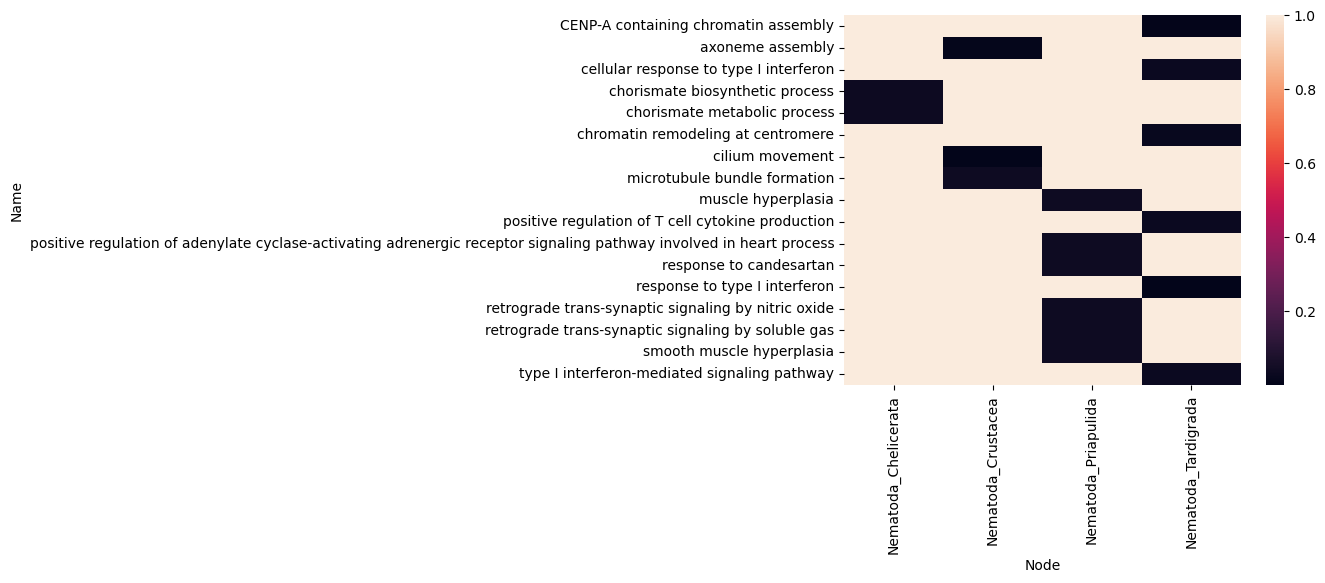

In [58]:
sns.heatmap(sang)

In [ ]:
f_n11

In [140]:
go_fm=pd.DataFrame(f_list,columns =['Ontology','Term','Name','Enrich','Study','Pop','p_fdr_bh','p_uncor'])

In [142]:
go_fm[go_fm.p_fdr_bh<0.01]

,Ontology,Term,Name,Enrich,Study,Pop,p_fdr_bh,p_uncor
0,BP,GO:0009628,response to abiotic stimulus,e,34,853,0.000335,2.101042e-08
1,BP,GO:0055085,transmembrane transport,e,25,519,0.000411,8.236625e-08
2,BP,GO:1902074,response to salt,e,17,262,0.000947,2.371633e-07
3,BP,GO:0097066,response to thyroid hormone,e,7,34,0.001529,5.156287e-07
4,BP,GO:0003008,system process,e,31,854,0.002177,9.818026e-07
5,BP,GO:0009605,response to external stimulus,e,39,1253,0.002647,1.326504e-06
6,BP,GO:0034220,monoatomic ion transmembrane transport,e,19,379,0.004147,2.286128e-06
7,BP,GO:0009725,response to hormone,e,23,565,0.008425,5.910945e-06
3474,CC,GO:0005886,plasma membrane,e,47,1529,0.000408,6.131417e-08
3475,CC,GO:0071944,cell periphery,e,47,1634,0.001529,5.361898e-07


In [139]:
f_list=[[l.NS,l.GO,l.name,l.enrichment,l.ratio_in_study[0],l.ratio_in_pop[0],l.p_fdr_bh,l.p_uncorrected] for  l in f_n11]

### Purge redundancy

In [3]:
cre=pd.read_csv("Cafe_priap_GO.tsv",sep='\t')